In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_style("whitegrid")

df_fe = pd.read_csv("../data/processed/housing_features.csv")
print(df_fe.shape)   # should be (250000, ...) with the new columns included

(250000, 39)


# Price & Size Analysis

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_style("whitegrid")

#### 1.	What is the distribution of property prices?

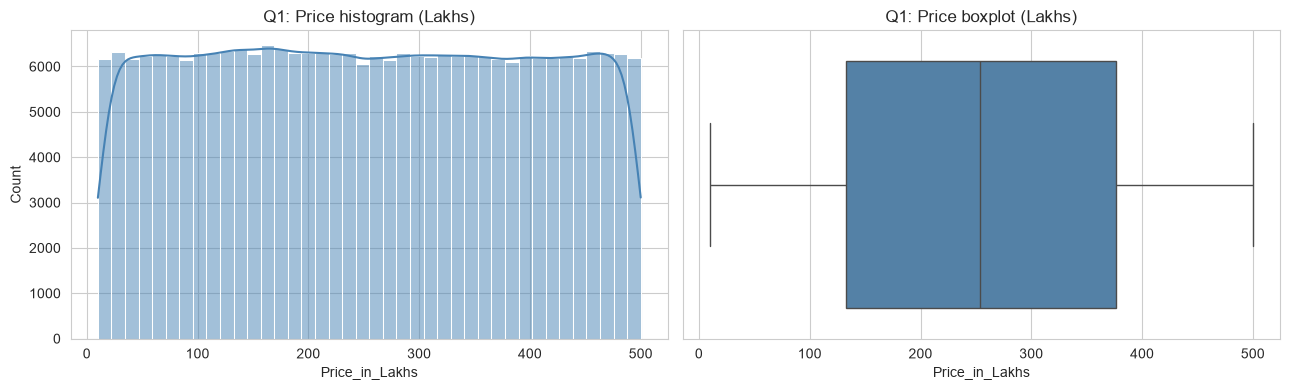

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_fe["Price_in_Lakhs"], bins=40, kde=True, color="steelblue", ax=ax[0])
ax[0].set_title("Q1: Price histogram (Lakhs)")
sns.boxplot(x=df_fe["Price_in_Lakhs"], color="steelblue", ax=ax[1])
ax[1].set_title("Q1: Price boxplot (Lakhs)")
plt.tight_layout()
plt.show()

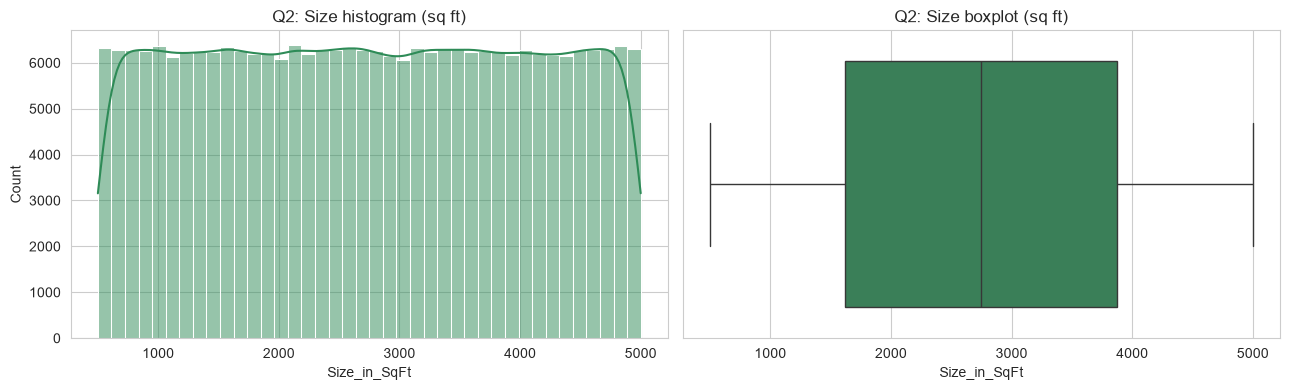

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_fe["Size_in_SqFt"], bins=40, kde=True, color="seagreen", ax=ax[0])
ax[0].set_title("Q2: Size histogram (sq ft)")
sns.boxplot(x=df_fe["Size_in_SqFt"], color="seagreen", ax=ax[1])
ax[1].set_title("Q2: Size boxplot (sq ft)")
plt.tight_layout()
plt.show()

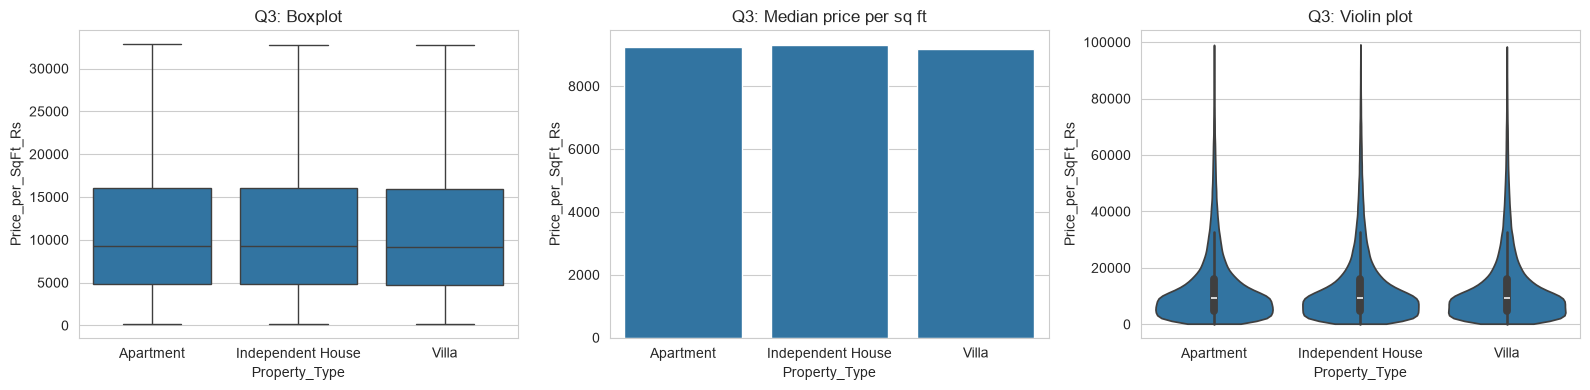

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=df_fe, x="Property_Type", y="Price_per_SqFt_Rs", showfliers=False, ax=ax[0])
ax[0].set_title("Q3: Boxplot")
sns.barplot(data=df_fe, x="Property_Type", y="Price_per_SqFt_Rs", estimator="median", errorbar=None, ax=ax[1])
ax[1].set_title("Q3: Median price per sq ft")
sns.violinplot(data=df_fe, x="Property_Type", y="Price_per_SqFt_Rs", cut=0, ax=ax[2])
ax[2].set_title("Q3: Violin plot")
plt.tight_layout()
plt.show()

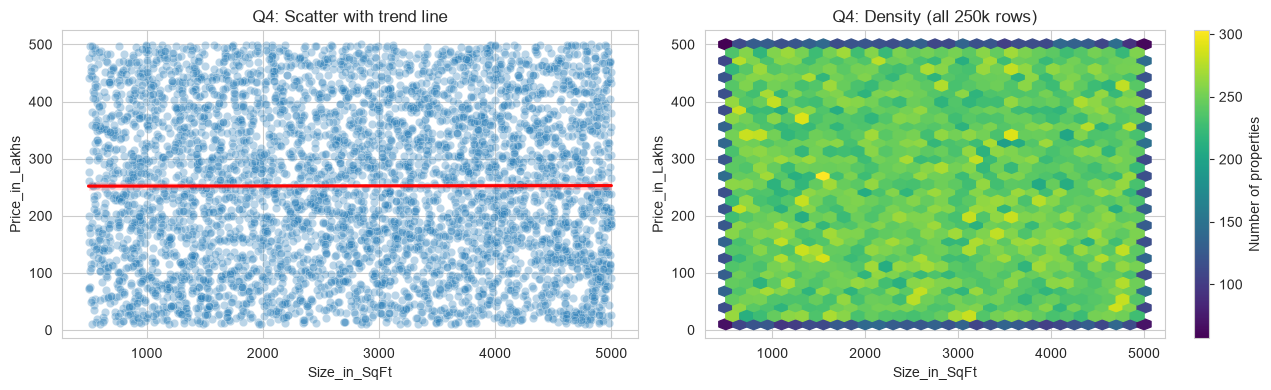

Correlation: -0.003


In [9]:
sample = df_fe.sample(5000, random_state=42)   # sample keeps the scatter readable
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=sample, x="Size_in_SqFt", y="Price_in_Lakhs", alpha=0.3, ax=ax[0])
sns.regplot(data=sample, x="Size_in_SqFt", y="Price_in_Lakhs", scatter=False, color="red", ax=ax[0])
ax[0].set_title("Q4: Scatter with trend line")
hb = ax[1].hexbin(df_fe["Size_in_SqFt"], df_fe["Price_in_Lakhs"], gridsize=30, cmap="viridis")
fig.colorbar(hb, ax=ax[1], label="Number of properties")
ax[1].set_title("Q4: Density (all 250k rows)")
ax[1].set_xlabel("Size_in_SqFt"); ax[1].set_ylabel("Price_in_Lakhs")
plt.tight_layout()
plt.show()
print("Correlation:", round(df_fe["Size_in_SqFt"].corr(df_fe["Price_in_Lakhs"]), 3))

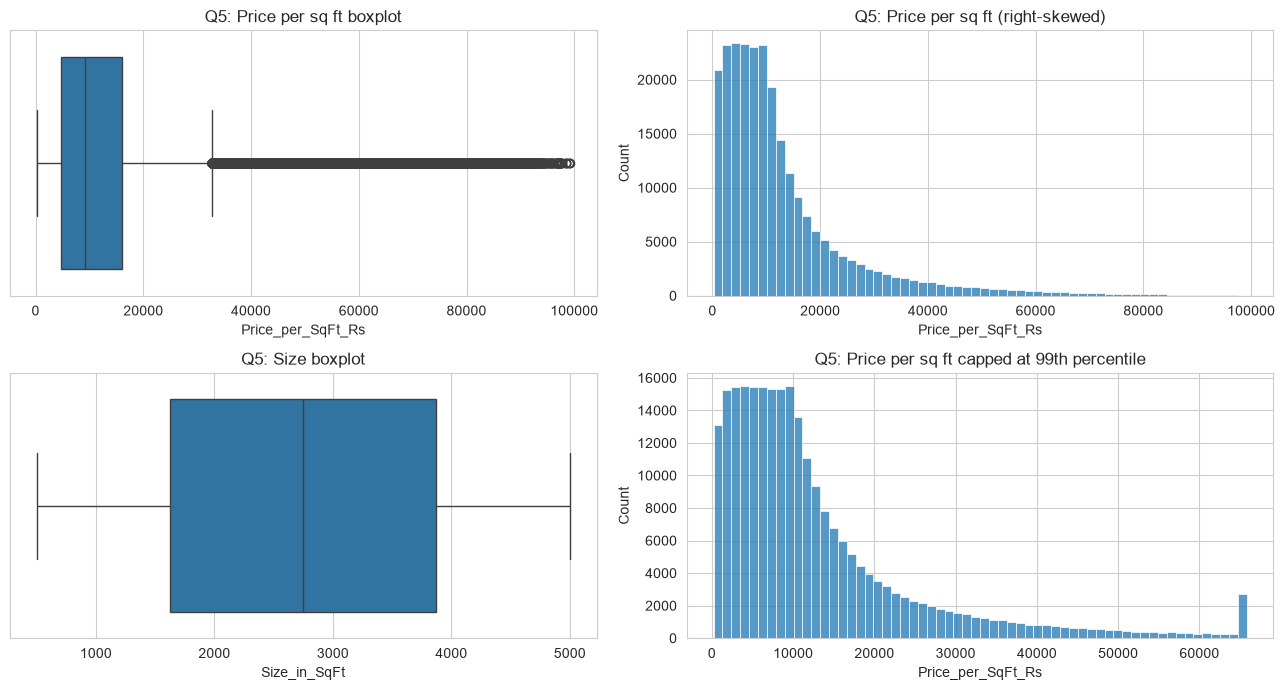

Price_per_SqFt_Rs: 19723 outliers (7.9%)
Size_in_SqFt: 0 outliers (0.0%)


In [10]:
cap = df_fe["Price_per_SqFt_Rs"].quantile(0.99)
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
sns.boxplot(x=df_fe["Price_per_SqFt_Rs"], ax=ax[0, 0]);  ax[0, 0].set_title("Q5: Price per sq ft boxplot")
sns.histplot(df_fe["Price_per_SqFt_Rs"], bins=60, ax=ax[0, 1]);  ax[0, 1].set_title("Q5: Price per sq ft (right-skewed)")
sns.boxplot(x=df_fe["Size_in_SqFt"], ax=ax[1, 0]);  ax[1, 0].set_title("Q5: Size boxplot")
sns.histplot(df_fe["Price_per_SqFt_Rs"].clip(upper=cap), bins=60, ax=ax[1, 1])
ax[1, 1].set_title("Q5: Price per sq ft capped at 99th percentile")
plt.tight_layout()
plt.show()

for c in ["Price_per_SqFt_Rs", "Size_in_SqFt"]:
    q1, q3 = df_fe[c].quantile([0.25, 0.75]); iqr = q3 - q1
    n = ((df_fe[c] < q1 - 1.5 * iqr) | (df_fe[c] > q3 + 1.5 * iqr)).sum()
    print(f"{c}: {n} outliers ({n / len(df_fe):.1%})")